# DS203 Project - Model Training and Evaluation

Uses `DS203_model_data.csv` from the preprocessing notebook.

1. majority-class baseline
2. tune logistic regression / decision tree / random forest with cross-validation (training set)
3. compare on the validation set
4. one test-set check
5. numerical vs categorical vs combined features
6. interpretation: coefficients, permutation importance, misclassified countries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

In [ ]:
data = pd.read_csv("DS203_model_data.csv")

num_cols = ["gdp_growth", "log_inflation", "log_unemployment", "log_infant_mortality",
            "electricity", "internet", "agriculture", "industry", "log_trade"]
cat_cols = ["region", "DominantSector"]
class_names = ["Low", "Medium/High", "Very High"]

train = data[data["split"] == "train"]
val = data[data["split"] == "validation"]
test = data[data["split"] == "test"]

X_train, y_train = train[num_cols + cat_cols], train["y"]
X_val, y_val = val[num_cols + cat_cols], val["y"]
X_test, y_test = test[num_cols + cat_cols], test["y"]

print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)
#print(y_train.value_counts()

train: (115, 11) val: (39, 11) test: (39, 11)


Preprocessing (from the preprocessing notebook): median imputation + `StandardScaler` for numerical
columns, "Missing" category + `OneHotEncoder(handle_unknown='ignore')` for categorical ones.

In [3]:
def make_preprocessor(num_list, cat_list):
    transformers = []
    if len(num_list) > 0:
        numeric_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        transformers.append(("num", numeric_transformer, num_list))
    if len(cat_list) > 0:
        categorical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])
        transformers.append(("cat", categorical_transformer, cat_list))
    return ColumnTransformer(transformers=transformers)


def make_pipe(model, num_list=num_cols, cat_list=cat_cols):
    return Pipeline(steps=[
        ("prep", make_preprocessor(num_list, cat_list)),
        ("model", model)
    ])

In [4]:
# balanced accuracy = average recall across the 3 classes, read off the confusion matrix diagonal
def balanced_acc(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    recall_per_class = cm.diagonal() / cm.sum(axis=1)
    return recall_per_class.mean()

## 1. Majority-class baseline

Always predicts the most common training class. our model needs to beat this.

In [5]:
# value_counts() is already sorted highest first, so the top index is the majority class
majority_class = y_train.value_counts().index[0]
print("majority class:", class_names[majority_class])

baseline_train = np.array([majority_class] * len(y_train))
baseline_val = np.array([majority_class] * len(y_val))

print("train macro F1:", round(f1_score(y_train, baseline_train, average="macro"), 3))
print("val macro F1:", round(f1_score(y_val, baseline_val, average="macro"), 3))

majority class: Medium/High
train macro F1: 0.216
val macro F1: 0.218


## 2. Tuning with cross-validation

`GridSearchCV(cv=5, scoring='f1_macro')` on the training set only, same `<step>__<param>` syntax
as the sklearn pipeline notes. Grids kept small since there are only 115 training countries.

In [6]:
results = []
models = {}
best_params = {}

def tune(name, pipe, param_grid):
    grid = GridSearchCV(pipe, param_grid=param_grid, cv=5, scoring="f1_macro")
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring="f1_macro")
    val_f1 = f1_score(y_val, best_model.predict(X_val), average="macro")

    models[name] = best_model
    best_params[name] = grid.best_params_
    results.append([name, cv_scores.mean(), cv_scores.std(), val_f1])
    print(name, "- best params:", grid.best_params_)
    print(f"   CV macro F1 = {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}, val macro F1 = {val_f1:.3f}")

In [7]:
tune("Logistic Regression",
     make_pipe(LogisticRegression(max_iter=1000)),
     {"model__C": [0.01, 0.1, 1, 10, 100],
      "model__class_weight": [None, "balanced"]})

Logistic Regression - best params: {'model__C': 1, 'model__class_weight': 'balanced'}
   CV macro F1 = 0.829 +/- 0.109, val macro F1 = 0.639


In [8]:
tune("Decision Tree",
     make_pipe(DecisionTreeClassifier(random_state=42)),
     {"model__max_depth": [2, 3, 4, 5, None],
      "model__min_samples_leaf": [1, 3, 5],
      "model__class_weight": [None, "balanced"]})

Decision Tree - best params: {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 1}
   CV macro F1 = 0.827 +/- 0.063, val macro F1 = 0.701


In [9]:
tune("Random Forest",
     make_pipe(RandomForestClassifier(n_estimators=200, random_state=42)),
     {"model__max_depth": [3, 5, None],
      "model__min_samples_leaf": [1, 3],
      "model__class_weight": [None, "balanced"]})

Random Forest - best params: {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 1}
   CV macro F1 = 0.887 +/- 0.082, val macro F1 = 0.726


In [10]:
# put the baseline in the same table (dict of Series/list -> DataFrame, no pd.concat needed)
model_names = ["Baseline (majority)"] + [r[0] for r in results]
cv_mean = [f1_score(y_train, baseline_train, average="macro")] + [r[1] for r in results]
cv_std = [0.0] + [r[2] for r in results]
val_f1_list = [f1_score(y_val, baseline_val, average="macro")] + [r[3] for r in results]

results_table = pd.DataFrame({
    "model": model_names,
    "CV mean F1": cv_mean,
    "CV std F1": cv_std,
    "validation F1": val_f1_list,
})
results_table.round(3)

,model,CV mean F1,CV std F1,validation F1
0,Baseline (majority),0.216,0.000,0.218
1,Logistic Regression,0.829,0.109,0.639
2,Decision Tree,0.827,0.063,0.701
3,Random Forest,0.887,0.082,0.726


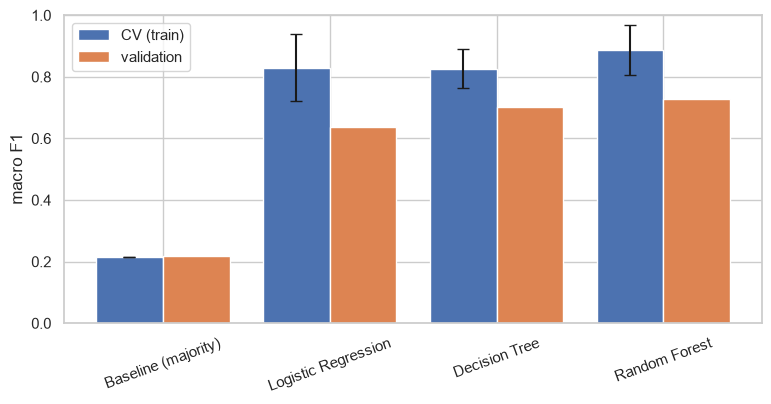

In [11]:
x_pos = np.arange(len(results_table))
plt.figure(figsize=(9, 4))
plt.bar(x_pos - 0.2, results_table["CV mean F1"], width=0.4, yerr=results_table["CV std F1"], capsize=4, label="CV (train)")
plt.bar(x_pos + 0.2, results_table["validation F1"], width=0.4, label="validation")
plt.xticks(x_pos, results_table["model"], rotation=20)
plt.ylabel("macro F1")
plt.ylim(0, 1)
plt.legend()
plt.show()

All three models are far above the baseline. Random forest looks best in CV; logistic regression and
the decision tree are close behind. Validation scores are noisier (only 39 countries, 5 of them Low).

## 3. Test set evaluation

First and only use of the test set.

In [12]:
baseline_test = np.array([majority_class] * len(y_test))

test_names = ["Baseline (majority)"] + list(models.keys())
test_acc, test_bal_acc, test_f1 = [], [], []
for name in test_names:
    pred = baseline_test if name == "Baseline (majority)" else models[name].predict(X_test)
    test_acc.append(accuracy_score(y_test, pred))
    test_bal_acc.append(balanced_acc(y_test, pred))
    test_f1.append(f1_score(y_test, pred, average="macro"))

test_table = pd.DataFrame({
    "model": test_names, "accuracy": test_acc, "balanced accuracy": test_bal_acc, "macro F1": test_f1,
})
test_table.round(3)

,model,accuracy,balanced accuracy,macro F1
0,Baseline (majority),0.487,0.333,0.218
1,Logistic Regression,0.795,0.806,0.769
2,Decision Tree,0.795,0.801,0.781
3,Random Forest,0.795,0.752,0.765


In [13]:
for name in models:
    pred = models[name].predict(X_test)
    print("=" * 50)
    print(name)
    print(classification_report(y_test, pred, target_names=class_names))

Logistic Regression
              precision    recall  f1-score   support

         Low       0.57      0.80      0.67         5
 Medium/High       0.87      0.68      0.76        19
   Very High       0.82      0.93      0.88        15

    accuracy                           0.79        39
   macro avg       0.75      0.81      0.77        39
weighted avg       0.81      0.79      0.79        39

Decision Tree
              precision    recall  f1-score   support

         Low       0.67      0.80      0.73         5
 Medium/High       0.82      0.74      0.78        19
   Very High       0.81      0.87      0.84        15

    accuracy                           0.79        39
   macro avg       0.77      0.80      0.78        39
weighted avg       0.80      0.79      0.79        39

Random Forest
              precision    recall  f1-score   support

         Low       0.75      0.60      0.67         5
 Medium/High       0.79      0.79      0.79        19
   Very High       0.81    

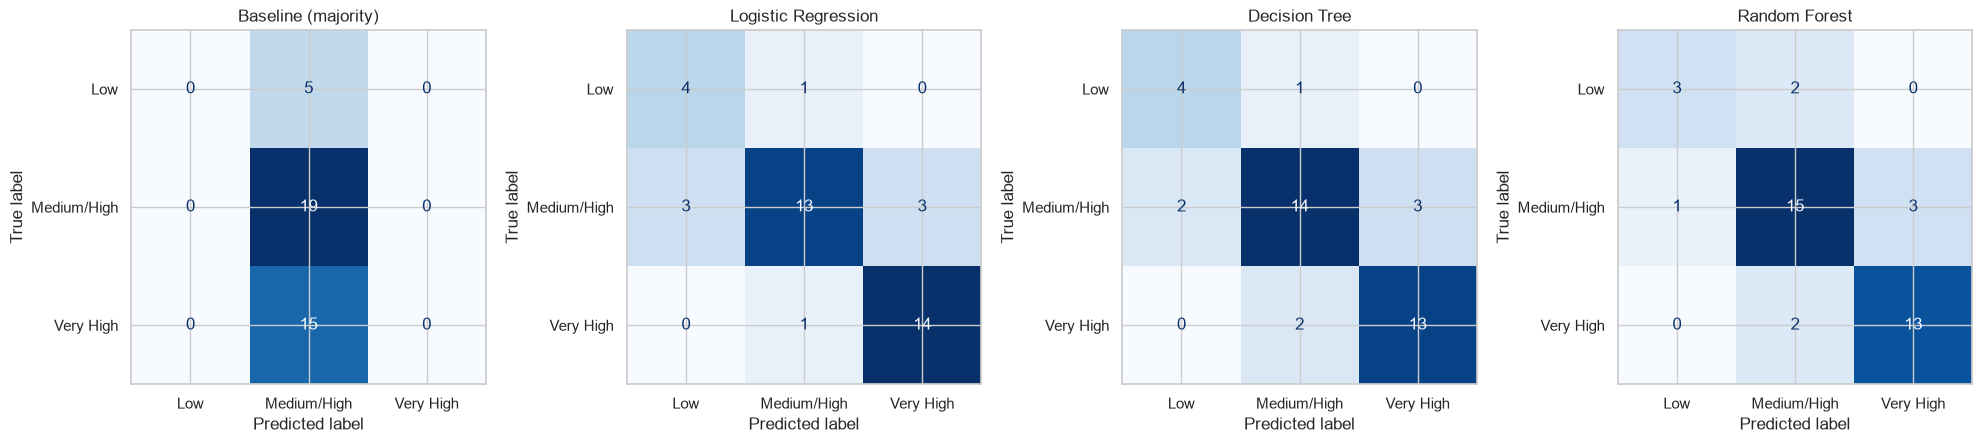

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

all_preds = {"Baseline (majority)": baseline_test}
for name in models:
    all_preds[name] = models[name].predict(X_test)

i = 0
for name, pred in all_preds.items():
    cm = confusion_matrix(y_test, pred, labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=axes[i], cmap="Blues", colorbar=False)
    axes[i].set_title(name)
    i = i + 1

plt.tight_layout()
plt.show()

The three real models end up close to each other on the test set, all clearly ahead of the baseline.
Most mistakes are between neighbouring classes (Low/Medium-High or Medium-High/Very High), not Low vs Very High.

## 4. Numerical vs categorical vs combined

Same tuned hyperparameters, changing only which columns go in.

In [15]:
feature_sets = {
    "numerical only": (num_cols, []),
    "categorical only": ([], cat_cols),
    "combined": (num_cols, cat_cols),
}

fs_rows = []
for set_name, (n_list, c_list) in feature_sets.items():
    for model_name in ["Logistic Regression", "Random Forest"]:
        if model_name == "Logistic Regression":
            pipe = make_pipe(LogisticRegression(max_iter=1000), n_list, c_list)
        else:
            pipe = make_pipe(RandomForestClassifier(n_estimators=200, random_state=42), n_list, c_list)
        pipe.set_params(**best_params[model_name])
        scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1_macro")
        fs_rows.append([set_name, model_name, scores.mean()])

fs_table = pd.DataFrame(fs_rows, columns=["features", "model", "CV mean F1"])
fs_table.round(3)

,features,model,CV mean F1
0,numerical only,Logistic Regression,0.833
1,numerical only,Random Forest,0.840
2,categorical only,Logistic Regression,0.639
3,categorical only,Random Forest,0.557
4,combined,Logistic Regression,0.829
5,combined,Random Forest,0.887


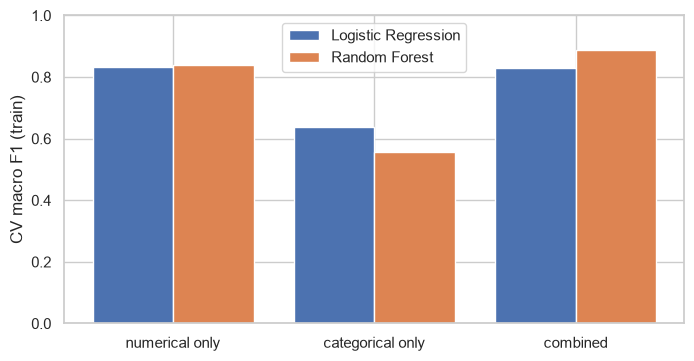

In [16]:
# build one column per model, instead of fs_table.pivot(...)

set_names = list(feature_sets.keys())
lr_f1 = [fs_table.loc[(fs_table["features"] == s) & (fs_table["model"] == "Logistic Regression"), "CV mean F1"].values[0] for s in set_names]
rf_f1 = [fs_table.loc[(fs_table["features"] == s) & (fs_table["model"] == "Random Forest"), "CV mean F1"].values[0] for s in set_names]

x_pos = np.arange(len(set_names))
plt.figure(figsize=(8, 4))
plt.bar(x_pos - 0.2, lr_f1, width=0.4, label="Logistic Regression")
plt.bar(x_pos + 0.2, rf_f1, width=0.4, label="Random Forest")
plt.xticks(x_pos, set_names)
plt.ylabel("CV macro F1 (train)")
plt.ylim(0, 1)
plt.legend()
plt.show()

Numerical features do most of the work (around 0.83-0.88 CV F1 on their own). Categorical features
alone are well above the baseline but clearly weaker. Adding them to the numerical set barely changes
the score either way - region and DominantSector mostly repeat what the indicators already say.

## 5. Interpretation

### 5.1 Logistic regression coefficients

One set of coefficients per class. Features are standardised so sizes can be compared roughly.
Several indicators are correlated with each other (see the EDA), so read these as rough directions, not exact effects.

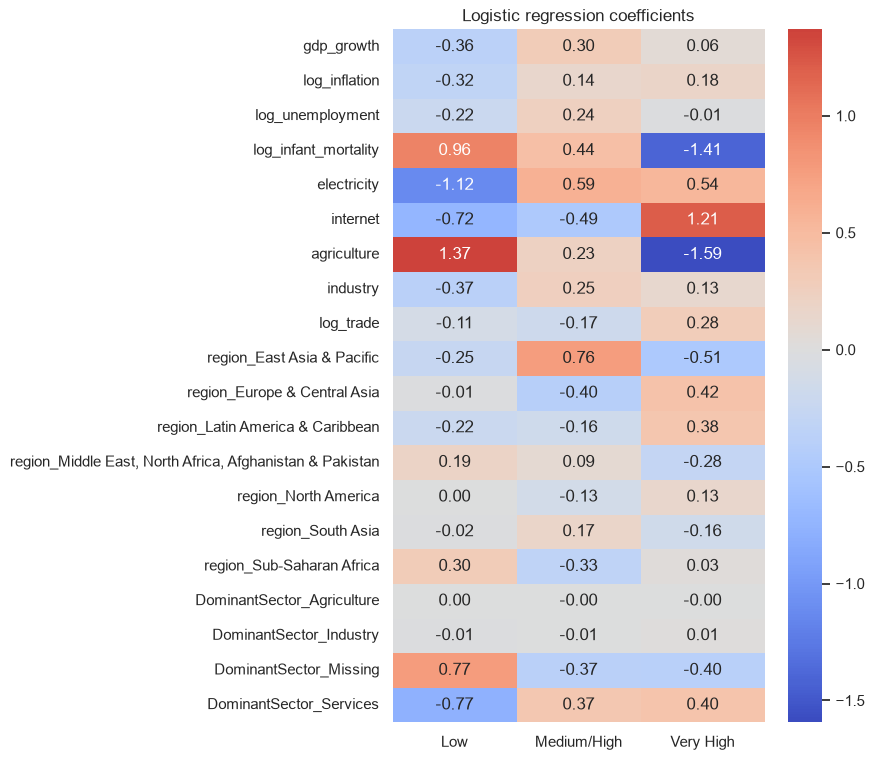

In [17]:
lr_model = models["Logistic Regression"]
lr_names = lr_model.named_steps["prep"].get_feature_names_out()
lr_names = [f.replace("num__", "").replace("cat__", "") for f in lr_names]

coef_table = pd.DataFrame(lr_model.named_steps["model"].coef_.T, index=lr_names, columns=class_names)

plt.figure(figsize=(6, 9))
sns.heatmap(coef_table, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Logistic regression coefficients")
plt.show()

### 5.2 Random forest permutation importance (by hand)

Shuffle one column at a time (`np.random.choice(..., replace=False)` to permute it), predict again,
and see how much macro F1 drops. Bigger drop = model relies on that feature more. Done on
validation + test together (not used for training), repeated 10 times per column and averaged.

random forest macro F1 on val+test: 0.757


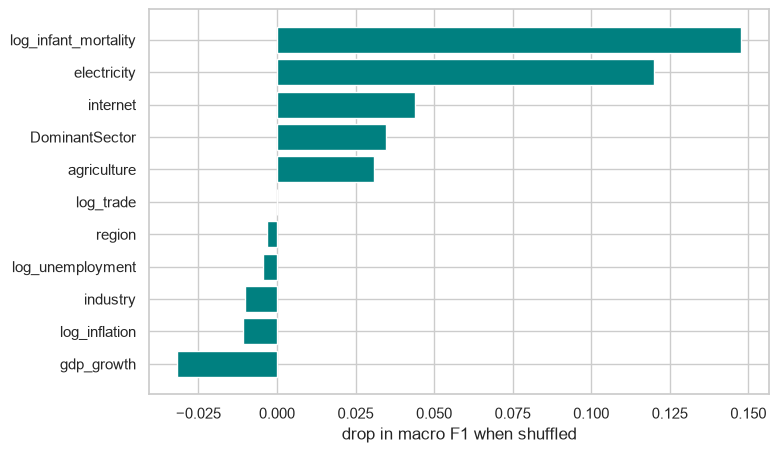

,feature,mean drop in F1
3,log_infant_mortality,0.148
4,electricity,0.120
5,internet,0.044
10,DominantSector,0.035
6,agriculture,0.031
8,log_trade,0.000
9,region,-0.003
2,log_unemployment,-0.004
7,industry,-0.010
1,log_inflation,-0.011


In [18]:
rf_model = models["Random Forest"]

# validation + test rows, picked out with a boolean mask instead of pd.concat
hold_mask = (data["split"] == "validation") | (data["split"] == "test")
X_hold = data.loc[hold_mask, num_cols + cat_cols]
y_hold = data.loc[hold_mask, "y"]

base_f1 = f1_score(y_hold, rf_model.predict(X_hold), average="macro")
print("random forest macro F1 on val+test:", round(base_f1, 3))

np.random.seed(42)
perm_rows = []
for col in num_cols + cat_cols:
    drops = []
    for repeat in range(10):
        X_shuffled = X_hold.copy()
        shuffled_values = np.random.choice(X_shuffled[col].values, size=len(X_shuffled), replace=False)
        X_shuffled[col] = shuffled_values
        new_f1 = f1_score(y_hold, rf_model.predict(X_shuffled), average="macro")
        drops.append(base_f1 - new_f1)
    perm_rows.append([col, np.mean(drops)])
    #print(col, drops)  # checking the individual repeats

perm_table = pd.DataFrame(perm_rows, columns=["feature", "mean drop in F1"]).sort_values("mean drop in F1")

plt.figure(figsize=(8, 5))
plt.barh(perm_table["feature"], perm_table["mean drop in F1"], color="teal")
plt.xlabel("drop in macro F1 when shuffled")
plt.show()

perm_table.sort_values("mean drop in F1", ascending=False).round(3)

Random forest relies mostly on infant mortality and electricity access - shuffling either one drops
macro F1 the most. Region barely matters to the forest even though it looked informative in the EDA,
probably because the indicators already carry the same information.

### 5.3 Misclassified countries

In [19]:
check = test[["country", "hdi_2023", "region"]].copy()
check["true_class"] = y_test.map({0: "Low", 1: "Medium/High", 2: "Very High"})

lr_pred = pd.Series(lr_model.predict(X_test), index=X_test.index).map({0: "Low", 1: "Medium/High", 2: "Very High"})
rf_pred = pd.Series(rf_model.predict(X_test), index=X_test.index).map({0: "Low", 1: "Medium/High", 2: "Very High"})
check["LogReg"] = lr_pred
check["RandomForest"] = rf_pred

wrong = check[(check["true_class"] != check["LogReg"]) | (check["true_class"] != check["RandomForest"])]
wrong.sort_values("hdi_2023")

,country,hdi_2023,region,true_class,LogReg,RandomForest
190,"Yemen, Rep.",0.470,"Middle East, North Africa, Afghanistan & Pakistan",Low,Medium/High,Medium/High
38,"Congo, Dem. Rep.",0.522,Sub-Saharan Africa,Low,Low,Medium/High
126,Nigeria,0.560,Sub-Saharan Africa,Medium/High,Low,Low
133,Papua New Guinea,0.576,East Asia & Pacific,Medium/High,Low,Medium/High
179,Uganda,0.582,Sub-Saharan Africa,Medium/High,Low,Medium/High
95,Lebanon,0.752,"Middle East, North Africa, Afghanistan & Pakistan",Medium/High,Very High,Medium/High
86,Jordan,0.754,"Middle East, North Africa, Afghanistan & Pakistan",Medium/High,Medium/High,Very High
105,Maldives,0.766,South Asia,Medium/High,Very High,Very High
10,Azerbaijan,0.789,Europe & Central Asia,Medium/High,Very High,Very High
1,Albania,0.810,Europe & Central Asia,Very High,Medium/High,Medium/High


Most of the misclassified countries sit right next to the 0.550 or 0.800 cut-off, so a small
difference in score decides the class. A few others (like countries missing several indicators)
get filled in with training medians, which can push them toward the wrong class.

## 6. Limitations

- **Class imbalance**: only 26 of 193 countries are Low. Macro F1 / balanced accuracy were used so this class isn't ignored, but with 5 Low countries in the test set, one mistake moves Low recall by 0.2.
- **Small sample**: 193 countries total, 115 for training. CV/validation/test scores don't always agree, and small gaps between models shouldn't be over-read.
- **Missing data**: more common in Low and conflict-affected countries. Median imputation can make those countries look more "typical" than they are.
- **Indicator-year mismatch**: HDI is for 2023, a few indicator values are from 2021/2022.
- **The target itself**: 3 classes come from cutting a continuous score at 0.550/0.800 (given for this project, not an official UNDP grouping), so countries near a cut-off are hard to classify almost by definition.
- **Association, not causation**: the models show which indicators go with each HDI group, not that changing one of them would change a country's HDI.